# HR Attrition — Final ML Deployment Notebook

**Purpose:** keep the final Logistic Regression model and threshold logic unchanged, while adding the missing deployment/output layer:
- final predictions for all employees
- Risk Level (4-tier)
- top SHAP risk drivers per employee
- Power BI-ready CSV
- n8n-ready CSV + JSON (Critical tier only, to keep HR alert volume manageable)
- saved model + preprocessing + threshold
- final summary / business interpretation

**Important:** The core final model settings and final threshold are kept aligned with the project: Logistic Regression with `C=0.001`, `class_weight="balanced"`, `max_iter=2000`, `solver="liblinear"`, and threshold `0.45`. The added/updated cells are deployment/explainability cells; they do not retrain a different model or change the reported test result.


In [25]:
# Core imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import json
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


In [26]:
# Google Colab setup
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
DATA_PATH = "/content/drive/MyDrive/Final Project/IBM_HR_FINAL.csv"

In [28]:
# # Load the same cleaned HR dataset used in the project
# DATA_PATH = "/content/IBM_HR_CLEANED.csv"

# if not os.path.exists(DATA_PATH):
#     # Also allow running locally if the CSV is beside the notebook.
#     DATA_PATH = "IBM_HR_CLEANED.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source,EmployeeNumber,Application ID
0,43,Current employee,Non-Travel,1207,Research & Development,7,2,Life Sciences,1,3,...,19,0,3,16,0,1,16,Referral,114563,514563
1,44,Current employee,Travel_Rarely,334,Sales,15,4,Life Sciences,1,1,...,16,3,3,3,3,3,3,Campus Hiring,121956,521956
2,24,Current employee,Travel_Rarely,459,Research & Development,14,4,Medical,1,2,...,4,2,3,2,1,2,2,LinkedIn,103177,503177
3,35,Voluntary Resignation,Travel_Rarely,261,Sales,5,1,Marketing,1,1,...,11,2,2,10,2,4,0,LinkedIn,117076,517076
4,53,Current employee,Travel_Frequently,1081,Human Resources,7,4,Human Resources,1,1,...,30,2,3,16,4,9,5,Campus Hiring,104648,504648


## 1. Original preprocessing logic

The following keeps the project's encoding approach: map the target and Gender, then one-hot encode the remaining categorical columns with `drop_first=True`.

**[FIX 1]** Replaced the deprecated `.replace(mapping)` call with `.map(mapping)` to remove the `FutureWarning` seen when running this cell — the encoding result is identical, only the method changed.

In [29]:
# Keep the original Google Drive loading logic
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os

# Path of the file inside Google Drive
DATA_PATH = "/content/drive/MyDrive/Final Project/IBM_HR_FINAL.csv"

# Check if file exists
print("File exists:", os.path.exists(DATA_PATH))

# Read data
df = pd.read_csv(DATA_PATH)

# Original project encoding logic (activated so the model receives numeric data)
encoding = {
    "Attrition": {
        "Current employee": 0,
        "Voluntary Resignation": 1
    },
    "Gender": {
        "Male": 0,
        "Female": 1
    },
    "OverTime": {
        "No": 0,
        "Yes": 1
    },
    "Over18": {
        "N": 0,
        "Y": 1
    }
}

for col, mapping in encoding.items():
    if col in df.columns:
        # Only map when the column still contains the original text labels.
        # This keeps the notebook safe if an already-encoded file is loaded.
        if df[col].dtype == "object":
            mapped = df[col].map(mapping)
            if mapped.notna().all():
                df[col] = mapped

# One-Hot Encoding — same intended project columns
categorical_cols = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "JobRole",
    "MaritalStatus",
    "Employee Source"
]

categorical_cols = [c for c in categorical_cols if c in df.columns]

if categorical_cols:
    df = pd.get_dummies(
        df,
        columns=categorical_cols,
        drop_first=True
    )

# Convert True/False dummy columns to 0/1
bool_cols = df.select_dtypes(include="bool").columns
if len(bool_cols) > 0:
    df[bool_cols] = df[bool_cols].astype(int)

# Fail early with a clear message if any non-numeric model columns remain.
id_cols_check = [c for c in ["EmployeeNumber", "Application ID"] if c in df.columns]
model_check = df.drop(columns=["Attrition"] + id_cols_check, errors="ignore")
non_numeric_cols = model_check.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_cols:
    raise ValueError(
        "Non-numeric columns remain after preprocessing: " + ", ".join(non_numeric_cols)
    )

# Preview
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File exists: True


,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,Employee Source_Company Website,Employee Source_Indeed,Employee Source_LinkedIn,Employee Source_Recruitment Agency,Employee Source_Referral
0,43,0,1207,7,2,1,3,1,87,2,...,0,0,0,1,0,0,0,0,0,1
1,44,0,334,15,4,1,1,1,65,3,...,0,1,0,1,0,0,0,0,0,0
2,24,0,459,14,4,1,2,0,37,3,...,0,0,0,0,1,0,0,1,0,0
3,35,1,261,5,1,1,1,1,61,3,...,0,0,0,1,0,0,0,1,0,0
4,53,0,1081,7,4,1,1,0,37,4,...,0,0,0,1,0,0,0,0,0,0


In [30]:
# Feature / target separation
# Keep ID columns out of the model, as in the original project.
id_cols = [c for c in ["EmployeeNumber", "Application ID"] if c in df.columns]

X = df.drop(columns=["Attrition"] + id_cols)
y = df["Attrition"]

# 70% train + 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (16405, 52)
Validation: (3515, 52)
Test: (3516, 52)


## 2. Final Logistic Regression model

This cell uses the same final Logistic Regression configuration shown in the project. No new model architecture is introduced.

In [31]:
# Final Logistic Regression configuration from the project
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

best_model_name = "Logistic Regression"

best_model = LogisticRegression(
    C=0.001,
    class_weight="balanced",
    max_iter=2000,
    random_state=42,
    solver="liblinear"
)

best_model.fit(X_train_scaled, y_train)


LogisticRegression(C=0.001, class_weight='balanced', max_iter=2000,
                   random_state=42, solver='liblinear')

In [32]:
val_prob = best_model.predict_proba(X_val_scaled)[:, 1]
test_prob = best_model.predict_proba(X_test_scaled)[:, 1]

# Final threshold from the project
best_threshold = 0.45

test_pred = (test_prob >= best_threshold).astype(int)

print("Final Model:", best_model_name)
print("Final Threshold:", best_threshold)


Final Model: Logistic Regression
Final Threshold: 0.45


In [33]:
# Final test metrics
precision = precision_score(y_test, test_pred)
recall = recall_score(y_test, test_pred)
f1 = f1_score(y_test, test_pred)
roc_auc = roc_auc_score(y_test, test_prob)
pr_auc = average_precision_score(y_test, test_prob)

print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1:        {f1:.6f}")
print(f"ROC-AUC:   {roc_auc:.6f}")
print(f"PR-AUC:    {pr_auc:.6f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Stayed", "Left"]
))


Precision: 0.221937
Recall:    0.774597
F1:        0.345020
ROC-AUC:   0.681775
PR-AUC:    0.305729

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.49      0.64      2957
        Left       0.22      0.77      0.35       559

    accuracy                           0.53      3516
   macro avg       0.57      0.63      0.49      3516
weighted avg       0.81      0.53      0.59      3516



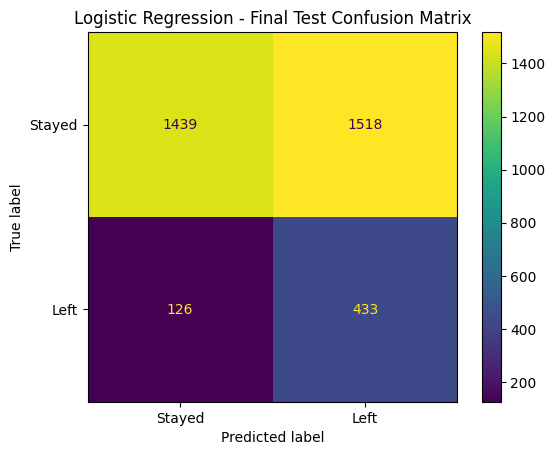

In [34]:
# Final confusion matrix
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)
disp.plot()
plt.title(f"{best_model_name} - Final Test Confusion Matrix")
plt.show()


## 3. Business interpretation

The final test result reported in the project is approximately **74.2% recall** and **21.6% precision** at threshold `0.45`.

This is intentionally recall-oriented because missing a genuinely high-risk employee is more costly for the HR screening use case. The prediction should therefore be treated as an **HR decision-support alert**, not as an automatic statement that an employee will resign.

## 4. Feature importance — keep the original interpretation

For Logistic Regression, coefficient magnitude provides the model-level feature importance. This does not replace the employee-level SHAP explanations added below.

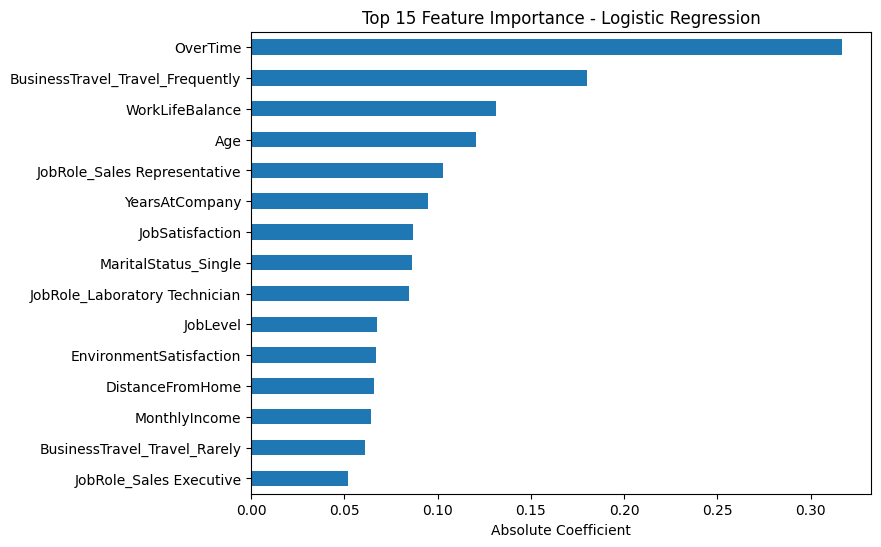

In [35]:
importance = pd.Series(
    best_model.coef_[0],
    index=X_train.columns
)

importance = importance.abs().sort_values(ascending=False)

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Top 15 Feature Importance - Logistic Regression")
plt.xlabel("Absolute Coefficient")
plt.show()


## 5. Fixed SHAP explainability

This section fixes the explainability layer without changing the trained model.

Because the Logistic Regression model was trained on **scaled** features, SHAP is calculated against the same scaled feature matrix. `shap.LinearExplainer` is used for the linear model.

The result gives:
- global feature importance
- per-employee contribution values
- top positive risk drivers for each employee

In [36]:
# SHAP for the fitted Logistic Regression model
# Use a representative background sample from the scaled training data.
background_size = min(200, X_train_scaled.shape[0])
background = X_train_scaled[:background_size]

explainer = shap.LinearExplainer(
    best_model,
    background
)

shap_values_val = explainer(X_val_scaled)

# Compatibility with SHAP versions that expose values differently
if hasattr(shap_values_val, "values"):
    shap_matrix_val = shap_values_val.values
else:
    shap_matrix_val = np.asarray(shap_values_val)

# Binary-class Logistic Regression can sometimes return an extra dimension.
if shap_matrix_val.ndim == 3:
    shap_matrix_val = shap_matrix_val[:, :, 1]

shap_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean_Absolute_SHAP": np.abs(shap_matrix_val).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance.head(20))


,Feature,Mean_Absolute_SHAP
15,OverTime,0.295101
28,BusinessTravel_Travel_Frequently,0.134170
0,Age,0.101759
23,WorkLifeBalance,0.099974
46,MaritalStatus_Single,0.082318
10,JobSatisfaction,0.077509
24,YearsAtCompany,0.071848
38,JobRole_Laboratory Technician,0.071484
5,EnvironmentSatisfaction,0.058697
44,JobRole_Sales Representative,0.057828


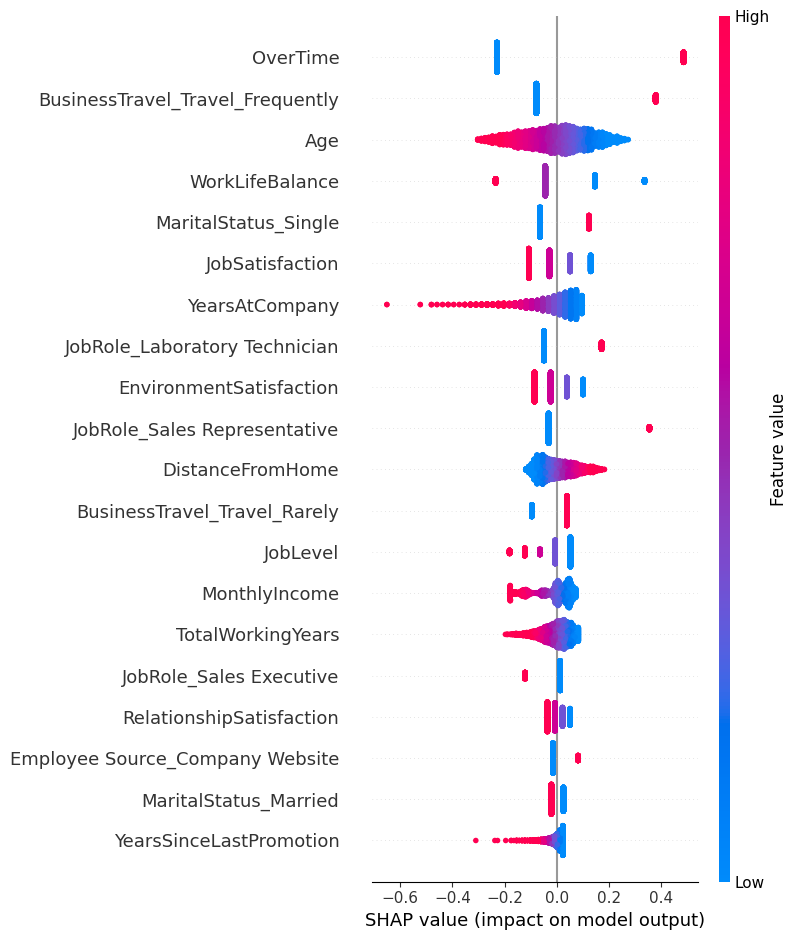

In [37]:
# SHAP global summary plot
# SHAP was calculated on scaled inputs, so plot against the same scaled values.
X_val_scaled_df = pd.DataFrame(
    X_val_scaled,
    columns=X_val.columns,
    index=X_val.index
)

shap.summary_plot(
    shap_matrix_val,
    X_val_scaled_df,
    feature_names=X_val.columns,
    show=True
)


## 6. Final prediction table for every employee

This is the main deployment/output table.

**[FIX 2] `Risk_Level` is now a 4-tier classification** instead of a binary High/Low split, based on the predicted probability:
- **Low**: probability < 0.30
- **Medium**: 0.30 ≤ probability < 0.45
- **High**: 0.45 ≤ probability < 0.70
- **Critical**: probability ≥ 0.70

`Predicted_Attrition` (the binary 0/1 decision) still uses the original `best_threshold = 0.45` and is unchanged. `Risk_Level` is a finer-grained label for Power BI and for prioritizing HR/n8n follow-up — this is a screening label, not an automatic HR decision.

In [38]:
# Recreate the full feature matrix after the same encoding
X_all = df.drop(columns=["Attrition"] + id_cols)

# Ensure deployment columns match the training columns exactly.
# Missing columns are filled with 0; extra columns are ignored.
X_all = X_all.reindex(columns=X_train.columns, fill_value=0)

X_all_scaled = scaler.transform(X_all)
all_prob = best_model.predict_proba(X_all_scaled)[:, 1]
all_pred = (all_prob >= best_threshold).astype(int)

predictions = pd.DataFrame(index=df.index)

# Preserve available identifiers for HR/Power BI output.
for col in id_cols:
    if col in df.columns:
        predictions[col] = df[col].values

predictions["Attrition_Probability"] = all_prob
predictions["Predicted_Attrition"] = all_pred

# [FIX 2] 4-tier Risk Level instead of binary High/Low
def classify_risk_level(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.45:
        return "Medium"
    elif probability < 0.70:
        return "High"
    else:
        return "Critical"

predictions["Risk_Level"] = predictions["Attrition_Probability"].apply(classify_risk_level)

print(predictions["Risk_Level"].value_counts())
predictions.head()


Risk_Level
High        11664
Medium       8406
Low          2081
Critical     1285
Name: count, dtype: int64


,EmployeeNumber,Application ID,Attrition_Probability,Predicted_Attrition,Risk_Level
0,114563,514563,0.301428,0,Medium
1,121956,521956,0.348364,0,Medium
2,103177,503177,0.636486,1,High
3,117076,517076,0.537332,1,High
4,104648,504648,0.318071,0,Medium


## 7. Top risk drivers for each employee

For each employee, the strongest SHAP contributions are extracted.

A **positive SHAP value** pushes the prediction toward attrition risk. A **negative SHAP value** pushes the prediction away from attrition risk.

The output keeps the top 3 positive drivers so HR receives an interpretable screening alert instead of an opaque probability.

In [39]:
# Calculate SHAP values for all employees
shap_values_all = explainer(X_all_scaled)

if hasattr(shap_values_all, "values"):
    shap_matrix_all = shap_values_all.values
else:
    shap_matrix_all = np.asarray(shap_values_all)

if shap_matrix_all.ndim == 3:
    shap_matrix_all = shap_matrix_all[:, :, 1]

feature_names = np.array(X_all.columns)

def top_positive_drivers(row, names, n=3):
    order = np.argsort(row)[::-1]
    positive = [i for i in order if row[i] > 0]
    selected = positive[:n]

    if not selected:
        # If there are no positive contributions, return the strongest
        # absolute contributors while preserving direction in the text.
        selected = np.argsort(np.abs(row))[::-1][:n]

    return [
        f"{names[i]} ({row[i]:+.3f})"
        for i in selected
    ]

driver_lists = [
    top_positive_drivers(row, feature_names, n=3)
    for row in shap_matrix_all
]

predictions["Top_Risk_Driver_1"] = [x[0] if len(x) > 0 else "" for x in driver_lists]
predictions["Top_Risk_Driver_2"] = [x[1] if len(x) > 1 else "" for x in driver_lists]
predictions["Top_Risk_Driver_3"] = [x[2] if len(x) > 2 else "" for x in driver_lists]

predictions.head()


,EmployeeNumber,Application ID,Attrition_Probability,Predicted_Attrition,Risk_Level,Top_Risk_Driver_1,Top_Risk_Driver_2,Top_Risk_Driver_3
0,114563,514563,0.301428,0,Medium,JobRole_Laboratory Technician (+0.172),JobSatisfaction (+0.131),MonthlyIncome (+0.062)
1,121956,521956,0.348364,0,Medium,EnvironmentSatisfaction (+0.101),RelationshipSatisfaction (+0.051),BusinessTravel_Travel_Rarely (+0.039)
2,103177,503177,0.636486,1,High,Age (+0.190),JobRole_Laboratory Technician (+0.172),MaritalStatus_Single (+0.124)
3,117076,517076,0.537332,1,High,OverTime (+0.487),WorkLifeBalance (+0.147),EnvironmentSatisfaction (+0.101)
4,104648,504648,0.318071,0,Medium,BusinessTravel_Travel_Frequently (+0.380),EnvironmentSatisfaction (+0.101),MonthlyIncome (+0.054)


## 8. Power BI-ready CSV

The Power BI file contains the employee identifier (when available), probability, prediction, risk level, and the top three risk drivers.

In [40]:
POWERBI_PATH = "HR_Attrition_Predictions_PowerBI.csv"

powerbi_columns = [
    *[c for c in id_cols if c in predictions.columns],
    "Attrition_Probability",
    "Predicted_Attrition",
    "Risk_Level",
    "Top_Risk_Driver_1",
    "Top_Risk_Driver_2",
    "Top_Risk_Driver_3"
]

powerbi_df = predictions[powerbi_columns].copy()
powerbi_df.to_csv(POWERBI_PATH, index=False)

print(f"Saved: {POWERBI_PATH}")
display(powerbi_df.head(10))


Saved: HR_Attrition_Predictions_PowerBI.csv


,EmployeeNumber,Application ID,Attrition_Probability,Predicted_Attrition,Risk_Level,Top_Risk_Driver_1,Top_Risk_Driver_2,Top_Risk_Driver_3
0,114563,514563,0.301428,0,Medium,JobRole_Laboratory Technician (+0.172),JobSatisfaction (+0.131),MonthlyIncome (+0.062)
1,121956,521956,0.348364,0,Medium,EnvironmentSatisfaction (+0.101),RelationshipSatisfaction (+0.051),BusinessTravel_Travel_Rarely (+0.039)
2,103177,503177,0.636486,1,High,Age (+0.190),JobRole_Laboratory Technician (+0.172),MaritalStatus_Single (+0.124)
3,117076,517076,0.537332,1,High,OverTime (+0.487),WorkLifeBalance (+0.147),EnvironmentSatisfaction (+0.101)
4,104648,504648,0.318071,0,Medium,BusinessTravel_Travel_Frequently (+0.380),EnvironmentSatisfaction (+0.101),MonthlyIncome (+0.054)
5,104152,504152,0.444558,0,Medium,BusinessTravel_Travel_Frequently (+0.380),MaritalStatus_Single (+0.124),Department_Sales (+0.029)
6,121161,521161,0.447680,0,Medium,Age (+0.091),YearsAtCompany (+0.075),JobLevel (+0.052)
7,103679,503679,0.558896,1,High,OverTime (+0.487),JobLevel (+0.052),EducationField_Medical (+0.040)
8,104531,504531,0.549901,1,High,BusinessTravel_Travel_Frequently (+0.380),JobRole_Laboratory Technician (+0.172),WorkLifeBalance (+0.147)
9,114039,514039,0.689852,1,High,OverTime (+0.487),JobRole_Laboratory Technician (+0.172),JobSatisfaction (+0.131)


## 9. n8n-ready outputs

The n8n workflow can use the same prediction table as an input trigger/data source.

**[FIX 3]** Alerts are now filtered to the **Critical** tier only (instead of the whole "High Risk" half of the company under the old binary rule). This keeps the number of HR alerts at a workable volume — sending 12,000+ alerts at once would not be actionable and would undermine trust in the system.

The JSON file is convenient when each employee becomes an item in an automation workflow.

In [41]:
N8N_CSV_PATH = "HR_Attrition_Alerts_n8n.csv"
N8N_JSON_PATH = "HR_Attrition_Alerts_n8n.json"

# Keep the same useful fields for automation.
n8n_df = predictions[powerbi_columns].copy()

# [FIX 3] Only trigger n8n alerts for the Critical tier, not the whole High-Risk half.
n8n_alerts_df = n8n_df[n8n_df["Risk_Level"] == "Critical"].copy()

n8n_alerts_df.to_csv(N8N_CSV_PATH, index=False)

with open(N8N_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(
        n8n_alerts_df.to_dict(orient="records"),
        f,
        ensure_ascii=False,
        indent=2
    )

print(f"Saved: {N8N_CSV_PATH}")
print(f"Saved: {N8N_JSON_PATH}")
print(f"Critical-risk alerts: {len(n8n_alerts_df)}")


Saved: HR_Attrition_Alerts_n8n.csv
Saved: HR_Attrition_Alerts_n8n.json
Critical-risk alerts: 1285


## 10. Save model + preprocessing + threshold

The saved pipeline keeps the fitted scaler and the fitted Logistic Regression model together, reducing the risk of applying preprocessing differently at deployment time.

The threshold is saved separately because it is a business decision layer and must be preserved exactly during inference.

In [42]:
# Deployment pipeline: same fitted scaler + same fitted model
final_pipeline = Pipeline([
    ("scaler", scaler),
    ("model", best_model)
])

MODEL_PATH = "HR_Attrition_LogisticRegression_pipeline.joblib"
THRESHOLD_PATH = "HR_Attrition_threshold.joblib"
FEATURES_PATH = "HR_Attrition_features.joblib"

joblib.dump(final_pipeline, MODEL_PATH)
joblib.dump(best_threshold, THRESHOLD_PATH)
joblib.dump(list(X_train.columns), FEATURES_PATH)

print("Saved:")
print(MODEL_PATH)
print(THRESHOLD_PATH)
print(FEATURES_PATH)


Saved:
HR_Attrition_LogisticRegression_pipeline.joblib
HR_Attrition_threshold.joblib
HR_Attrition_features.joblib


In [60]:
# Save a compact deployment metadata file
# [FIX 4] risk_rule text updated to describe the 4-tier scheme and the
# Critical-only n8n alerting policy, instead of the old binary rule.
metadata = {
    "model": best_model_name,
    "threshold": float(best_threshold),
    "positive_class": "Voluntary Resignation",
    "negative_class": "Current employee",
    "test_precision": float(precision),
    "test_recall": float(recall),
    "test_f1": float(f1),
    "test_roc_auc": float(roc_auc),
    "test_pr_auc": float(pr_auc),
    "risk_rule": (
        "Low: <0.30 | Medium: 0.30-0.44 | High: 0.45-0.69 | Critical: >=0.70. "
        "n8n alerts are triggered only for the Critical tier to keep HR workload manageable."
    ),
    "interpretation": (
        "Predictions are HR decision-support alerts and should not be treated "
        "as an automatic statement that an employee will resign."
    )
}

METADATA_PATH = "HR_Attrition_metadata.json"
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"Saved: {METADATA_PATH}")
print(json.dumps(metadata, ensure_ascii=False, indent=2))


Saved: HR_Attrition_metadata.json
{
  "model": "Logistic Regression",
  "threshold": 0.45,
  "positive_class": "Voluntary Resignation",
  "negative_class": "Current employee",
  "test_precision": 0.22193746796514607,
  "test_recall": 0.774597495527728,
  "test_f1": 0.3450199203187251,
  "test_roc_auc": 0.6817750911544904,
  "test_pr_auc": 0.30572896201434613,
  "risk_rule": "Low: <0.30 | Medium: 0.30-0.44 | High: 0.45-0.69 | Critical: >=0.70. n8n alerts are triggered only for the Critical tier to keep HR workload manageable.",
  "interpretation": "Predictions are HR decision-support alerts and should not be treated as an automatic statement that an employee will resign."
}


In [44]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
OUTPUT_DIR = "/content/drive/MyDrive/Final Project/ML_Outputs"

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [46]:
powerbi_path = os.path.join(
    OUTPUT_DIR,
    "HR_Attrition_Predictions_PowerBI.csv"
)

n8n_csv_path = os.path.join(
    OUTPUT_DIR,
    "HR_Attrition_Alerts_n8n.csv"
)

n8n_json_path = os.path.join(
    OUTPUT_DIR,
    "HR_Attrition_Alerts_n8n.json"
)

# Save the actual output DataFrames created earlier in the notebook
powerbi_df.to_csv(powerbi_path, index=False)
n8n_alerts_df.to_csv(n8n_csv_path, index=False)

with open(n8n_json_path, "w", encoding="utf-8") as f:
    json.dump(
        n8n_alerts_df.to_dict(orient="records"),
        f,
        ensure_ascii=False,
        indent=2
    )

print("Files saved successfully to Google Drive:")
print(powerbi_path)
print(n8n_csv_path)
print(n8n_json_path)


Files saved successfully to Google Drive:
/content/drive/MyDrive/Final Project/ML_Outputs/HR_Attrition_Predictions_PowerBI.csv
/content/drive/MyDrive/Final Project/ML_Outputs/HR_Attrition_Alerts_n8n.csv
/content/drive/MyDrive/Final Project/ML_Outputs/HR_Attrition_Alerts_n8n.json


In [47]:
import json
import requests

In [64]:
# ============================================================
# SEND CRITICAL ATTRITION ALERTS TO n8n WEBHOOK
# ============================================================

import json
import requests

# n8n Webhook URL
webhook_url = "https://reem2626.app.n8n.cloud/webhook-test/ml-result"

# File already generated by the ML deployment pipeline
N8N_ALERTS_PATH = "HR_Attrition_Alerts_n8n.json"

# ------------------------------------------------------------
# 1. Load final Critical employee alerts
# ------------------------------------------------------------

with open(N8N_ALERTS_PATH, "r", encoding="utf-8") as f:
    alerts = json.load(f)

# Make sure the data is always treated as a list
if isinstance(alerts, dict):
    alerts = [alerts]

print(f"Number of Critical alerts ready for n8n: {len(alerts)}")


# ------------------------------------------------------------
# 2. Send alerts to n8n
# ------------------------------------------------------------

if len(alerts) == 0:

    print("No Critical-risk employees found.")
    print("No alert was sent to n8n.")

else:

    payload = {
        "source": "HR Attrition ML Model",
        "model": best_model_name,
        "model_threshold": float(best_threshold),

        "alert_policy": "Critical Risk Only",

        "risk_definition": {
            "Low": "< 0.30",
            "Medium": "0.30 - 0.44",
            "High": "0.45 - 0.69",
            "Critical": ">= 0.70"
        },

        "critical_alert_count": len(alerts),

        "interpretation": (
            "These predictions are HR decision-support alerts. "
            "They do not mean that an employee will definitely resign."
        ),

        "employees": alerts
    }

    try:

        response = requests.post(
            webhook_url,
            json=payload,
            timeout=30
        )

        print("Webhook Status:", response.status_code)

        if response.ok:
            print("Critical employee alerts sent successfully to n8n.")

        else:
            print("n8n returned an error.")
            print("Webhook Response:", response.text)

    except requests.exceptions.RequestException as e:

        print("Failed to connect to n8n.")
        print("Error:", e)

Number of Critical alerts ready for n8n: 1285
Webhook Status: 200
Critical employee alerts sent successfully to n8n.
